# 01. Linear Regression — Executed Thesis Notebook

**Thesis:** *Towards Trustworthy Financial Time Series Forecasting: An Experimental Evaluation of Explainable Machine Learning Models for Stock Price Prediction*.

## Purpose and study position

This notebook fits and evaluates **ordinary least squares (OLS)** on S&P 500, DAX, NASDAQ Composite, DJIA, and the raw Monash Sunspot T1 series. It studies one- and five-step targets under rolling and expanding walk-forward evaluation. The design uses six folds per scheme and normally 252 test origins per fold. It produces observation-level predictions, fold metrics, feature attributions, stability diagnostics, faithfulness diagnostics, figures, and provenance.

The notebook contributes to all three research questions, but it does not answer them in isolation:

- **RQ1:** predictive accuracy and the accuracy–interpretability comparison; final seven-model rankings come from the matched-origin synthesis.
- **RQ2:** consecutive-fold attribution stability and descriptive regime differences.
- **RQ3:** additivity, interventions, surrogate or permutation agreement where applicable, and relative attribution; none of these establishes causal economic drivers.

**Configuration:** OLS on standardized lag_1, lag_5, lag_21, and lag_252, with exact linear attributions on the same standardized scale.

## How to read and run this notebook

Every code cell is preceded by a detailed explanation. Read the explanation first, then inspect the code and its stored output. The notebooks retain their stored execution outputs. Documentation was added without recalculating model predictions or numerical results.

Run the notebooks in numerical order from this `notebooks/` directory. The frozen inputs are in `../data/`; newly generated outputs are written to `../results/`. No internet download is used. The eighth notebook reads all seven model result folders and performs the cross-model synthesis.

## Thesis map

| Code cell | Main role | Main thesis sections | Research questions |
|---|---|---|---|
| 1 | Shared data, validation, metrics, explanation, and export pipeline | §4.2, §4.3, §4.5, §4.6, §4.7 | RQ1, RQ2, RQ3 |
| 2 | Data-coverage and fold-structure audit | §4.2.1, §4.3.2, §4.7 | RQ1; design support for RQ2 |
| 3 | Model fitting, forecasting, and native or post-hoc attribution | §2.2.1 and §4.4.1, §4.5.1 | RQ1, RQ2, RQ3 |
| 4 | Diagnostics, figures, tables, and evidence export | §5.1–§5.4; Appendices A–D | RQ1, RQ2, RQ3 |
| 5 | Independent read-back and checksum validation | §4.7; Appendices C–D | Evidence integrity for all RQs |

The model is situated theoretically in **§2.2.1 and §4.4.1**. Relevant thesis literature includes **James et al. (2013), Brockwell and Davis (2016), and Tsay (2005)**. The explanation diagnostics additionally follow the evaluation perspective in Molnar (2022), Biecek and Burzykowski (2021), Theissler et al. (2022), and Theissler (2024).


## Code Cell 1 — Shared Research Pipeline

**Purpose.** This cell defines the complete experimental contract and the reusable functions used later. It sets paths and constants, loads and verifies the frozen data, constructs supervised learning frames, creates leakage-aware walk-forward folds, defines regimes, computes metrics and statistical tests, evaluates explanations, and exports evidence. It does **not** fit the forecasting model yet.

**Thesis connection:** §4.1 Research Design; §4.2 Data; §4.3 Temporal Preprocessing and Feature Engineering; §4.5 Explainability Diagnostics; §4.6 Evaluation Framework; §4.7 Reproducibility and Experimental Setup. The resulting analyses feed §5.1–§5.4 and Chapters 6–8.

**Research questions:** RQ1 through predictive metrics and benchmark tests; RQ2 through common probes, stability measures, and regimes; RQ3 through attribution, additivity, interventions, permutation, and local-surrogate diagnostics.

**How to read the mathematics.** In the equations below, $t$ identifies an observation or forecast origin, $h$ is the forecast horizon, $j$ identifies a predictor or explanation channel, $y_t$ is the realized target, and $\hat y_t$ is its prediction. A signed attribution $\phi_{t,j}$ describes how one predictor contributes to a model output under the stated explanation method. The surrounding text defines additional symbols, explains why each calculation is needed, and states its interpretation limits. These equations describe the implemented computations; they do not by themselves establish causal economic relationships.

### 1. Imports, constants, and reproducibility

The imports provide array computing (`numpy`), tables (`pandas`), statistical functions (`scipy`), preprocessing and metrics (`scikit-learn`), figures (`matplotlib`), file hashing, timestamps, and package-version reporting. The non-interactive `Agg` backend writes figures without requiring a display.

The base seed is **20261017**. The three tree models use seeds 20261017 and 20261018; the other models use the base seed. The four predictors are `lag_1`, `lag_5`, `lag_21`, and `lag_252`. For financial data they represent approximately the previous session, week, month, and year of log returns; for Sunspot they are native-value lags. Horizons are 1 and 5. Static models use six folds, 40 probes, and four explained folds per scheme. Deep models use four folds, 30 probes, three explained folds, and a lookback of 21. The test span is 252, the minimum training window is 500, and the pre-test gap contains five purge rows plus five embargo rows. `N_RANDOM_CTRL=32` sets the number of random orderings used as intervention controls. `USE_EXTENDED_TRAINING=False` means that the executed experiment uses the standard settings documented in this notebook rather than the optional extended neural-training setting. With this setting, LSTM and simplified TFT training is capped at 25 epochs and still uses early stopping.

`sha256()` computes a cryptographic file fingerprint. `find_data()` searches the package's `../data/` directory and local fallback locations. The output directory is `../results/<model>_study`, with `tables/`, `figures/`, and `evidence/` subdirectories. These are path and documentation settings; they do not change model calculations.

### 2. Frozen data and target construction

For each financial index, the code reads `Date` and `Adj Close`, rejects duplicate dates, missing adjusted prices, and non-positive prices, and computes the one-session log return

$$
r_t=\log\!\left(\frac{P_t}{P_{t-1}}\right),
$$

where $P_t$ is the adjusted closing price. The first row has no previous price and is removed. Log returns are additive over time and avoid using price levels as if they were stationary. This operationalizes §2.1.1, §2.2.1, and §4.2.2 and follows the financial-time-series perspective of Tsay (2005).

The Sunspot CSV is sorted by date and checked against the original TSF entry `T1`. The TSF values are parsed into daily dates, merged one-to-one with the execution CSV, and required to produce **11,109 aligned rows with zero value mismatches**. The full TSF may contain more dates; only the frozen execution period is used. This supports the Monash benchmark connection in §3.3.3 and §4.2.1 and follows Godahewa et al. (2021). No network fallback or undocumented normalization is permitted.

`build_frames()` retains `source_row` so every lag-trimmed row can be mapped back to the raw series. It creates $x_{t,\ell}=r_{t-\ell}$ for financial data, or the corresponding native Sunspot lag, for $\ell\in\{1,5,21,252\}$. Financial targets are cumulative future log returns,

$$
y_t^{(h)}=\sum_{j=1}^h r_{t+j},\qquad h\in\{1,5\}.
$$

Sunspot targets are native future values, $y_t^{(h)}=s_{t+h}$. Rows without all lags or all targets are removed. This difference in target meaning is essential: a financial prediction is a future return, while a Sunspot prediction is a future value in the original units.

### 3. Walk-forward folds and common explanation probes

`make_folds()` builds chronological train and test intervals. Python intervals exclude the right endpoint. If a test block starts at $s$, training ends at $s-10$, leaving ten frame rows between supervised training and testing. Rolling training uses the latest 500 available training rows; expanding training starts at row zero and grows. A fold is accepted only if it has at least 20 test rows and 100 training rows; the planned configurations produce 6 folds per series and scheme.

The gap reduces leakage from overlapping future-return targets near the train/test boundary. It is part of the evaluation design, not a claim that every possible dependence has been removed. This implements §4.3.2 and connects to the evaluation-rigor discussion in López de Prado (2018), Ballarin (2024), Medeiros (2022), and Hu et al. (2026).

`explanation_positions()` chooses 40 evenly spaced, unique probe origins from the last explained test block through the frame end. Every probe is out-of-sample for every explained fold, and the same positions are reused across consecutive folds. Reuse permits matched stability comparisons, but it limits temporal diversity; it does not create independent replications. This is the common-probe design in §4.5.1 and a limitation discussed again in Chapter 7.

### 4. Descriptive regimes

For financial prices, `regimes()` computes 63-session rolling mean returns $\bar r_t$ and rolling standard deviations $\sigma_t$. Labels are assigned using full-series quantiles:

- **bull:** mean above its 60th percentile and volatility below its 80th percentile;
- **bear:** mean below its 40th percentile;
- **crisis:** volatility above its 95th percentile;
- **boundary:** all remaining defined observations.

The crisis rule is applied last and therefore overrides earlier labels. `frame_regimes()` maps these labels to modeling-frame dates; Sunspot receives `na`. These are **ex post descriptive strata**, not independently dated events, real-time trading signals, or proof of structural breaks. They implement §4.6.3 and support RQ2 in §5.2.2.

### 5. Prediction records, benchmarks, and metrics

`target_date()` finds the date exactly $h$ raw observations after the origin. `add_predictions()` exports each origin with its realized target, model prediction, benchmark predictions, dates, fold, and seed. Financial persistence is a zero cumulative future log return; Sunspot persistence is the current native value. The training-mean prediction is supplied by the model-specific fitting code from the exact supervised training interval.

`finalize_predictions()` computes $e_t=y_t-\hat y_t$, squared error $e_t^2$, and absolute error $|e_t|$, then aggregates by model, series, horizon, scheme, and fold:

$$
\mathrm{RMSE}=\sqrt{\frac1n\sum_t e_t^2},\qquad
\mathrm{MAE}=\frac1n\sum_t|e_t|,
$$

$$
R^2=1-\frac{\sum_t(y_t-\hat y_t)^2}{\sum_t(y_t-\bar y)^2},\qquad
\mathrm{DA}=\frac1n\sum_t\mathbf{1}\{\operatorname{sign}(y_t)=\operatorname{sign}(\hat y_t)\}.
$$

Here $n$ is the number of evaluated origins, $\bar y$ is the realized-target mean within the evaluation sample, and $\mathbf{1}\{\cdot\}$ equals one when the stated condition holds and zero otherwise. RMSE and MAE measure forecast-error magnitude, $R^2$ compares squared error with an evaluation-sample mean benchmark, and DA measures sign agreement.

DA is calculated only for financial return targets. A negative $R^2$ means performance is worse than predicting the evaluation-sample mean in that fold; it does not use the training-mean benchmark in its denominator. DA above 50% does not by itself demonstrate profitability. These definitions implement §4.6.1 and support RQ1 in §5.1.

### 6. Diebold–Mariano tests and multiple-comparison control

`benchmark_tests()` compares the model with persistence and the training mean using observation-level squared-error losses. For model A and benchmark B,

$$
d_t=(y_t-\hat y_{A,t})^2-(y_t-\hat y_{B,t})^2.
$$

A negative mean differential favors the model. `dm_hac()` centers $d_t$, estimates $\hat\gamma_k$ at lags $0,\ldots,h-1$, and uses the unweighted autocovariance sum

$$
\hat S=\hat\gamma_0+2\sum_{k=1}^{h-1}\hat\gamma_k,\qquad
DM=\frac{\bar d}{\sqrt{\hat S/n}},\qquad
p=2[1-\Phi(|DM|)].
$$

In these expressions, $\bar d$ is the mean loss differential, $\hat S$ estimates the long-run variance of that differential, $\hat\gamma_k$ is the lag-$k$ autocovariance, and $\Phi$ is the standard normal cumulative distribution function. The p-value is two-sided and describes evidence about a loss difference; it does not measure economic importance.

Thus the effective HAC lag is zero at horizon 1 and four at horizon 5. This implementation does not apply Bartlett weights. Fewer than 20 observations or a non-positive/non-finite variance yields missing values rather than a fabricated statistic. The synthesis notebook later improves the block handling by keeping autocovariances within contiguous matched or native fold blocks. The approach supports §4.6.1–§4.6.2 and §5.1.2–§5.1.4 and connects to Diebold (2007).

`bh_adjust()` implements Benjamini–Hochberg adjustment. For $m$ ordered valid p-values, it forms $p_{(i)}m/i$, enforces monotonicity from the largest to smallest rank, and caps values at one. In this notebook the adjustment is over the model's two benchmark tests within each series–horizon–scheme cell. The synthesis separately applies the 21-pair and 14-test families used in the thesis.

### 7. Faithfulness diagnostics

Exact linear, treeshap, or kernelshap attributions are constructed in code cell 3; this cell defines diagnostics that consume those attributions. For additive explanations, the checked identity is

$$
\hat f(x)\approx\phi_0+\sum_j\phi_j,\qquad
r_{\max}=\max_x\left|\hat f(x)-\phi_0-\sum_j\phi_j\right|.
$$

A small numerical residual supports additivity only. It does not prove that the ranking is behaviorally faithful or economically causal.

`di_curves()` and `di_curves_grouped()` rank features by mean absolute attribution and compare deletion/insertion with 32 seeded random orderings. At step $k$, deletion replaces the first $k$ features with standardized zero and records $\mathrm{MSE}_k^{del}$; insertion starts from all zeros and restores the first $k$ features, recording $\mathrm{MSE}_k^{ins}$. `_auc()` averages the trapezoidal area over the curve. Higher deletion area and lower insertion area than the random mean support the targeted intervention property. Deep interventions act on all 21 positions of a lag channel. Zero baselines and synthetic interventions can leave the natural data distribution, so these diagnostics are evidence about specific behavior, not universal proof. See §2.4.1, §4.5.3, and §5.3.1.

`permutation_importance_groups()` measures

$$
\Delta\mathrm{MSE}_j=\mathrm{MSE}(y,f(X^{(j)}))-\mathrm{MSE}(y,f(X)),
$$

where feature or lag channel $j$ is permuted across samples. Deep permutation preserves within-sequence order. The code compares PFI rankings with SHAP-style rankings using Spearman correlation. Dependent lag features and distribution shifts can make the methods disagree, as discussed in §2.4.3.

`lime_local()` implements a **LIME-style weighted local ridge surrogate**, not an external LIME-package run. It draws 200 fitting and 100 holdout samples from a standard-normal distribution, obtains black-box predictions, and fits ridge regression with weights

$$
w_i=\exp\!\left[-\frac{\|z_i-x\|^2}{2(0.75p)}\right],
$$

where $p$ is the flattened coordinate count. It reports holdout surrogate MSE and compares mean absolute surrogate coefficients with the main attribution ranking. Surrogate agreement and fidelity are separate from fidelity of the underlying forecast to reality. This follows the model-agnostic evaluation perspective in Molnar (2022) and Biecek and Burzykowski (2021).

### 8. Stability, figures, evidence, and audits

`run_posthoc_diagnostics()` assembles additivity, PFI–SHAP agreement, intervention areas and success indicators, local-surrogate fidelity and agreement, native–post-hoc agreement where available, signed attributions, and tree seed comparisons. `stability_analysis()` compares the same probe at consecutive folds using

$$
\rho=\operatorname{Spearman}(\mathbf a_{f},\mathbf a_{f+1}),\qquad
\cos(\mathbf a_f,\mathbf a_{f+1})=\frac{\mathbf a_f^\top\mathbf a_{f+1}}{\|\mathbf a_f\|\,\|\mathbf a_{f+1}\|},
$$

and an indicator for whether the largest absolute feature matches. High rank correlation can coexist with scale changes; cosine similarity is sensitive to direction and magnitude; top-feature agreement ignores the remaining ranks. Together they provide complementary RQ2 evidence for §4.5.2 and §5.2.1, not a single universal stability score.

`standard_figures()` creates fold-RMSE, attribution-magnitude, intervention, and regime-stability figures. `standard_export()` verifies expected coverage, finite predictions, RMSE recomputation, Sunspot alignment, and complete dates; records package versions, input hashes, timings, and implementation decisions; and writes CSV, PNG, JSON, and Markdown evidence. `json_safe()` converts numerical and date objects into portable JSON values. `FILE_SHA256.json` fingerprints the exported artifacts.

The exported evidence remains model-specific. Final RQ1 rankings require common origins in Notebook 08; RQ2 summaries describe explanation agreement rather than economic invariance; RQ3 diagnostics do not turn lag associations into causal mechanisms. These boundaries are central to §5.4, Chapters 6–8, and the explanation-evaluation concerns discussed by Theissler et al. (2022), Theissler (2024), and Arsenault, Wang, and Patenaude (2025).

**What to inspect in the stored output.** This long definition cell has no model-results table because its role is to prepare the pipeline. Data and fold coverage are displayed in Code Cell 2; model estimates and diagnostics appear in later cells.


In [1]:
MODEL = 'Linear'
EXECUTION_VERSION = 'thesis-execution-v1'

import os, sys, json, time, hashlib, warnings, platform
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as importlib_metadata
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, norm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RUN_STARTED = time.time()
SEED = 20261017
np.random.seed(SEED)
LAGS = [1, 5, 21, 252]
FEATURES = [f'lag_{l}' for l in LAGS]
USE_EXTENDED_TRAINING = False
HORIZONS = [1, 5]
IS_DEEP = MODEL in ('LSTM', 'TFT')
N_FOLDS = 4 if IS_DEEP else 6
TEST_SPAN, MIN_TRAIN, PURGE, EMBARGO = 252, 500, 5, 5
SCHEMES = ['rolling', 'expanding']
SEEDS = [SEED, SEED + 1] if MODEL in ('RandomForest', 'XGBoost', 'LightGBM') else [SEED]
EXPLAIN_FOLDS = 3 if IS_DEEP else 4
PROBE_N = 30 if IS_DEEP else 40
LOOKBACK = 21 if IS_DEEP else 0
N_RANDOM_CTRL = 32
OUT = Path.cwd().parent / 'results' / f'{MODEL}_study'
for sub in ('tables', 'figures', 'evidence'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(65536), b''):
            h.update(chunk)
    return h.hexdigest()


def find_data(names):
    for base in (Path.cwd().parent / 'data', Path.cwd() / 'data', Path.cwd(), Path.cwd().parent):
        for name in names:
            candidate = base / name
            if candidate.exists():
                return candidate
    return None


INDEX_FILES = {
    'sp500': 'sp500_observations.csv',
    'dax': 'dax_observations.csv',
    'nasdaq': 'nasdaq_observations.csv',
    'djia': 'djia_observations.csv'
}
SUNSPOT_FILE = 'monash_sunspot_no_missing_T1_85babb464a3e.csv'
SUNSPOT_TSF = 'sunspot_dataset_without_missing_values.tsf'
DATA, PROVENANCE = {}, {'data': {}, 'execution_version': EXECUTION_VERSION}

# Only the supplied, frozen inputs are used. No network fallback is permitted.
for sid, filename in INDEX_FILES.items():
    path = find_data([filename])
    if path is None:
        raise FileNotFoundError(f'Required frozen input not found: {filename}')
    frame = pd.read_csv(path, parse_dates=['Date'])
    if frame['Date'].duplicated().any() or frame['Adj Close'].isna().any() or (frame['Adj Close'] <= 0).any():
        raise ValueError(f'Invalid adjusted-price input: {sid}')
    frame['log_return'] = np.log(frame['Adj Close'] / frame['Adj Close'].shift(1))
    DATA[sid] = frame.iloc[1:].dropna().reset_index(drop=True)
    PROVENANCE['data'][sid] = {'path': str(path), 'sha256': sha256(path)}

sunspot_path = find_data([SUNSPOT_FILE])
tsf_path = find_data([SUNSPOT_TSF])
if sunspot_path is None or tsf_path is None:
    raise FileNotFoundError('The traceable Monash CSV and original TSF are both required.')
sunspot = pd.read_csv(sunspot_path)
sunspot['date'] = pd.to_datetime(sunspot['date'])
sunspot = sunspot.rename(columns={'date': 'Date'}).sort_values('Date').reset_index(drop=True)
DATA['monash_sunspot'] = sunspot
PROVENANCE['data']['monash_sunspot'] = {'path': str(sunspot_path), 'sha256': sha256(sunspot_path)}
PROVENANCE['data']['monash_sunspot_tsf'] = {'path': str(tsf_path), 'sha256': sha256(tsf_path)}

# Verify the execution CSV against every aligned value in the supplied original TSF.
tsf_text = tsf_path.read_text()
data_line = next(line for line in tsf_text.splitlines() if line.startswith('T1:'))
_, start_text, values_text = data_line.split(':', 2)
start_text = start_text.replace('00-00-00', '00:00:00')
tsf_values = np.asarray([float(v) for v in values_text.split(',')], dtype=float)
tsf_dates = pd.date_range(pd.to_datetime(start_text), periods=len(tsf_values), freq='D')
tsf_frame = pd.DataFrame({'Date': tsf_dates, 'tsf_value': tsf_values})
sunspot_check = DATA['monash_sunspot'][['Date', 'value']].merge(tsf_frame, on='Date', how='left', validate='one_to_one')
SUNSPOT_AUDIT = {
    'tsf_rows': int(len(tsf_frame)),
    'execution_rows': int(len(DATA['monash_sunspot'])),
    'aligned_rows': int(sunspot_check['tsf_value'].notna().sum()),
    'value_mismatches': int((sunspot_check['value'].astype(float) != sunspot_check['tsf_value']).sum()),
    'source_start': str(tsf_frame['Date'].min().date()),
    'source_end': str(tsf_frame['Date'].max().date()),
    'execution_start': str(DATA['monash_sunspot']['Date'].min().date()),
    'execution_end': str(DATA['monash_sunspot']['Date'].max().date())
}
assert SUNSPOT_AUDIT['aligned_rows'] == len(DATA['monash_sunspot']) == 11109
assert SUNSPOT_AUDIT['value_mismatches'] == 0
PROVENANCE['sunspot_source_verification'] = SUNSPOT_AUDIT


def build_frames(sid):
    source = DATA[sid]
    financial = sid != 'monash_sunspot'
    column = 'log_return' if financial else 'value'
    frame = source.copy()
    frame['source_row'] = np.arange(len(frame), dtype=int)
    for lag in LAGS:
        frame[f'lag_{lag}'] = frame[column].shift(lag)
    for horizon in HORIZONS:
        if financial:
            frame[f'target_h{horizon}'] = sum(frame[column].shift(-i) for i in range(1, horizon + 1))
        else:
            frame[f'target_h{horizon}'] = frame[column].shift(-horizon)
    return frame.iloc[max(LAGS):-max(HORIZONS)].dropna().reset_index(drop=True)


FRAMES = {sid: build_frames(sid) for sid in DATA}


def make_folds(n, scheme):
    folds = []
    for fold_id in range(N_FOLDS):
        test_start = ((n - N_FOLDS * TEST_SPAN + fold_id * TEST_SPAN) if scheme == 'rolling'
                      else (MIN_TRAIN + PURGE + EMBARGO + fold_id * TEST_SPAN))
        test_end = min(test_start + TEST_SPAN, n)
        train_end = test_start - PURGE - EMBARGO
        train_start = max(0, train_end - MIN_TRAIN) if scheme == 'rolling' else 0
        if test_end - test_start >= 20 and train_end - train_start >= 100:
            folds.append({'fold': fold_id, 'scheme': scheme,
                          'tr': (train_start, train_end), 'te': (test_start, test_end)})
    return folds


def explanation_positions(frame, scheme):
    """Matched origins from the last explained test block through the frame end.

    Every position is out-of-sample for every explained fold, while the wider
    span preserves bear/bull/crisis coverage instead of restricting RQ2 to one
    potentially quiet test block.
    """
    folds = [fo for fo in make_folds(len(frame), scheme) if fo['fold'] < EXPLAIN_FOLDS]
    last = folds[-1]
    start = last['te'][0] + LOOKBACK
    stop = len(frame)
    positions = np.unique(np.linspace(start, stop - 1, PROBE_N).astype(int))
    assert len(positions) == PROBE_N
    assert positions.min() >= last['te'][0] + LOOKBACK
    return positions


def regimes(prices, window=63):
    returns = np.diff(np.log(prices))
    mean = pd.Series(returns).rolling(window).mean()
    std = pd.Series(returns).rolling(window).std()
    labels = pd.Series('boundary', index=range(len(returns)))
    labels[(mean > mean.quantile(.6)) & (std < std.quantile(.8))] = 'bull'
    labels[mean < mean.quantile(.4)] = 'bear'
    labels[std > std.quantile(.95)] = 'crisis'
    return labels


def frame_regimes(sid, frame):
    if sid == 'monash_sunspot':
        return pd.Series('na', index=frame.index)
    source = DATA[sid]
    labels = regimes(source['Adj Close'].values)
    positions = np.clip(np.searchsorted(source['Date'].values, frame['Date'].values) - 1, 0, len(labels) - 1)
    return pd.Series(labels.values[positions], index=frame.index)


def target_date(sid, frame_position, horizon):
    frame = FRAMES[sid]
    source_row = int(frame['source_row'].iloc[frame_position]) + horizon
    return DATA[sid]['Date'].iloc[source_row]


def add_predictions(store, sid, horizon, scheme, fold, origin_positions, predictions, train_mean):
    frame = FRAMES[sid]
    financial = sid != 'monash_sunspot'
    origin_positions = np.asarray(origin_positions, dtype=int)
    predictions = np.asarray(predictions, dtype=float)
    assert len(origin_positions) == len(predictions)
    assert np.isfinite(predictions).all()
    for position, prediction in zip(origin_positions, predictions):
        realized = float(frame[f'target_h{horizon}'].iloc[position])
        origin_source_row = int(frame['source_row'].iloc[position])
        expected_target_date = DATA[sid]['Date'].iloc[origin_source_row + horizon]
        persistence = 0.0 if financial else float(frame['value'].iloc[position])
        store.append({
            'model': MODEL, 'series': sid, 'horizon': int(horizon), 'scheme': scheme,
            'fold': int(fold), 'origin_index': int(position),
            'origin_date': frame['Date'].iloc[position].strftime('%Y-%m-%d'),
            'target_date': expected_target_date.strftime('%Y-%m-%d'),
            'y_true': realized, 'y_pred': float(prediction),
            'random_walk_pred': float(persistence), 'train_mean_pred': float(train_mean),
            'seed': SEED
        })


def finalize_predictions(rows):
    predictions = pd.DataFrame(rows)
    predictions['error'] = predictions['y_true'] - predictions['y_pred']
    predictions['squared_error'] = predictions['error'] ** 2
    predictions['absolute_error'] = predictions['error'].abs()
    metric_rows = []
    keys = ['model', 'series', 'horizon', 'scheme', 'fold']
    for values, group in predictions.groupby(keys, sort=True):
        model, sid, horizon, scheme, fold = values
        metric_rows.append({
            'model': model, 'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
            'seed': SEED, 'rmse': float(np.sqrt(mean_squared_error(group['y_true'], group['y_pred']))),
            'mae': float(mean_absolute_error(group['y_true'], group['y_pred'])),
            'da': (float(np.mean(np.sign(group['y_true']) == np.sign(group['y_pred'])))
                   if sid != 'monash_sunspot' else np.nan),
            'r2': float(r2_score(group['y_true'], group['y_pred'])),
            'n_test': int(len(group)), 'status': 'complete'
        })
    return predictions, pd.DataFrame(metric_rows)


def dm_hac(loss_a, loss_b, horizon):
    """HAC Diebold–Mariano test on observation-level losses, with h-1 lags."""
    loss_a, loss_b = np.asarray(loss_a, float), np.asarray(loss_b, float)
    differential = loss_a - loss_b
    n = len(differential)
    if n < 20:
        return np.nan, np.nan
    centered = differential - differential.mean()
    long_run_variance = np.dot(centered, centered) / n
    for lag in range(1, min(max(horizon - 1, 0), 9) + 1):
        covariance = np.dot(centered[lag:], centered[:-lag]) / n
        long_run_variance += 2 * covariance
    if not np.isfinite(long_run_variance) or long_run_variance <= 0:
        return np.nan, np.nan
    statistic = differential.mean() / np.sqrt(long_run_variance / n)
    p_value = 2 * (1 - norm.cdf(abs(statistic)))
    return float(statistic), float(p_value)


def bh_adjust(p_values):
    p = np.asarray(p_values, float)
    result = np.full(len(p), np.nan)
    valid = np.flatnonzero(np.isfinite(p))
    if not len(valid):
        return result
    order = valid[np.argsort(p[valid])]
    ranked = p[order] * len(order) / np.arange(1, len(order) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    result[order] = np.minimum(ranked, 1.0)
    return result


def benchmark_tests(predictions):
    rows = []
    for (sid, horizon, scheme), group in predictions.groupby(['series', 'horizon', 'scheme']):
        group = group.sort_values('origin_index')
        for label, column in [('random_walk_or_persistence', 'random_walk_pred'),
                              ('training_mean', 'train_mean_pred')]:
            benchmark_loss = (group['y_true'] - group[column]) ** 2
            statistic, p_value = dm_hac(group['squared_error'], benchmark_loss, horizon)
            rows.append({'model': MODEL, 'series': sid, 'horizon': horizon, 'scheme': scheme,
                         'comparison': label, 'n': int(len(group)), 'dm': statistic, 'p_raw': p_value})
    result = pd.DataFrame(rows)
    result['p_bh_within_series_horizon_scheme'] = np.nan
    for _, indices in result.groupby(['series', 'horizon', 'scheme']).groups.items():
        result.loc[indices, 'p_bh_within_series_horizon_scheme'] = bh_adjust(result.loc[indices, 'p_raw'])
    return result


def _auc(values):
    return float(np.trapezoid(values, dx=1.0) / (len(values) - 1))


def di_curves(pred_fn, X, y, order, n_random=N_RANDOM_CTRL):
    n_features = X.shape[1]
    cases = [('model', order)] + [(f'r{i}', np.random.RandomState(SEED + i).permutation(n_features))
                                  for i in range(n_random)]
    output = {}
    for tag, ordering in cases:
        deletion_loss, insertion_loss = [], []
        for k in range(n_features + 1):
            deleted = X.copy()
            for feature in ordering[:k]:
                deleted[:, feature] = 0
            deletion_loss.append(mean_squared_error(y, pred_fn(deleted)))
            inserted = np.zeros_like(X)
            for feature in ordering[:k]:
                inserted[:, feature] = X[:, feature]
            insertion_loss.append(mean_squared_error(y, pred_fn(inserted)))
        output[tag] = (_auc(deletion_loss), _auc(insertion_loss))
    model_deletion, model_insertion = output['model']
    random_deletion = np.mean([output[f'r{i}'][0] for i in range(n_random)])
    random_insertion = np.mean([output[f'r{i}'][1] for i in range(n_random)])
    return {'del_auc_model': model_deletion, 'del_auc_random': random_deletion,
            'ins_auc_model': model_insertion, 'ins_auc_random': random_insertion,
            'faithful_deletion': bool(model_deletion > random_deletion),
            'faithful_insertion': bool(model_insertion < random_insertion)}


def di_curves_grouped(pred_fn, Z, y, order, n_random=N_RANDOM_CTRL):
    """Deep interventions permute the same four lag groups for model and random orderings."""
    n = len(Z)
    X = Z.reshape(n, LOOKBACK, len(FEATURES))
    cases = [('model', order)] + [(f'r{i}', np.random.RandomState(SEED + i).permutation(len(FEATURES)))
                                  for i in range(n_random)]
    output = {}
    for tag, ordering in cases:
        deletion_loss, insertion_loss = [], []
        for k in range(len(FEATURES) + 1):
            deleted = X.copy()
            for feature in ordering[:k]:
                deleted[:, :, feature] = 0
            deletion_loss.append(mean_squared_error(y, pred_fn(deleted.reshape(n, -1))))
            inserted = np.zeros_like(X)
            for feature in ordering[:k]:
                inserted[:, :, feature] = X[:, :, feature]
            insertion_loss.append(mean_squared_error(y, pred_fn(inserted.reshape(n, -1))))
        output[tag] = (_auc(deletion_loss), _auc(insertion_loss))
    model_deletion, model_insertion = output['model']
    random_deletion = np.mean([output[f'r{i}'][0] for i in range(n_random)])
    random_insertion = np.mean([output[f'r{i}'][1] for i in range(n_random)])
    return {'del_auc_model': model_deletion, 'del_auc_random': random_deletion,
            'ins_auc_model': model_insertion, 'ins_auc_random': random_insertion,
            'faithful_deletion': bool(model_deletion > random_deletion),
            'faithful_insertion': bool(model_insertion < random_insertion)}


def lime_local(pred_fn, x, rng, n=200, holdout=100):
    from sklearn.linear_model import Ridge
    Z = rng.normal(0, 1, (n + holdout, len(x)))
    weights = np.exp(-0.5 * np.sum((Z - x) ** 2, axis=1) / (0.75 * len(x)))
    y = pred_fn(Z)
    surrogate = Ridge(alpha=1e-8).fit(Z[:n], y[:n], sample_weight=weights[:n])
    fidelity = mean_squared_error(y[n:], surrogate.predict(Z[n:]))
    return surrogate.coef_, fidelity


def permutation_importance_groups(pred_fn, X, y, rng):
    baseline = mean_squared_error(y, pred_fn(X))
    values = []
    if IS_DEEP:
        n = len(X)
        sequences = X.reshape(n, LOOKBACK, len(FEATURES))
        for feature in range(len(FEATURES)):
            changed = sequences.copy()
            changed[:, :, feature] = changed[rng.permutation(n), :, feature]
            values.append(mean_squared_error(y, pred_fn(changed.reshape(n, -1))) - baseline)
    else:
        for feature in range(X.shape[1]):
            changed = X.copy()
            changed[:, feature] = rng.permutation(changed[:, feature])
            values.append(mean_squared_error(y, pred_fn(changed)) - baseline)
    return np.asarray(values)


def run_posthoc_diagnostics(explanations):
    faith_rows, importance_rows, attribution_rows, seed_rows = [], [], [], []
    method = ('KernelSHAP_lag_aggregated' if IS_DEEP else
              'exact_linear_SHAP' if MODEL == 'Linear' else 'TreeSHAP_full_ensemble')
    for key in sorted(explanations):
        sid, horizon, scheme, fold = key
        item = explanations[key]
        X, y, phi, positions = item['X'], item['y'], item['phi'], item['pr']
        pred_fn = item['pred_fn']
        importance = np.abs(phi).mean(axis=0)
        faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                           'model': MODEL, 'method': 'SHAP_additivity', 'metric': 'max_abs_residual',
                           'value': float(item['additivity_residual'])})
        for j, feature in enumerate(FEATURES):
            importance_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                                    'model': MODEL, 'feature': feature, 'mean_abs_shap': float(importance[j])})
        rng_pfi = np.random.RandomState(SEED + fold)
        pfi = permutation_importance_groups(pred_fn, X, y, rng_pfi)
        rho_pfi, _ = spearmanr(pfi, importance)
        faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                           'model': MODEL, 'method': 'PFI_vs_SHAP', 'metric': 'spearman_rho',
                           'value': float(rho_pfi)})
        intervention = (di_curves_grouped(pred_fn, X, y, np.argsort(-importance)) if IS_DEEP
                        else di_curves(pred_fn, X, y, np.argsort(-importance)))
        for metric, value in intervention.items():
            faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                               'model': MODEL, 'method': 'deletion_insertion_grouped' if IS_DEEP else 'deletion_insertion',
                               'metric': metric, 'value': value if isinstance(value, bool) else float(value)})
        rng = np.random.RandomState(SEED + fold)
        local = [lime_local(pred_fn, x, rng) for x in X[:min(20, len(X))]]
        coefficients = np.asarray([entry[0] for entry in local])
        if IS_DEEP:
            surrogate_importance = np.abs(coefficients.reshape(len(coefficients), LOOKBACK, len(FEATURES))).mean(axis=(0, 1))
        else:
            surrogate_importance = np.abs(coefficients).mean(axis=0)
        rho_lime, _ = spearmanr(surrogate_importance, importance)
        faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                           'model': MODEL, 'method': 'LIME_fidelity', 'metric': 'median_holdout_mse',
                           'value': float(np.median([entry[1] for entry in local]))})
        faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                           'model': MODEL, 'method': 'LIME_vs_SHAP', 'metric': 'spearman_rho',
                           'value': float(rho_lime)})
        if item.get('native') is not None:
            native_importance = item['native'].mean(axis=0)
            rho_native, _ = spearmanr(native_importance, importance)
            faith_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                               'model': MODEL, 'method': 'native_vs_posthoc', 'metric': 'spearman_rho',
                               'value': float(rho_native)})
        regimes_for_frame = frame_regimes(sid, FRAMES[sid])
        for probe_number, position in enumerate(positions):
            for j, feature in enumerate(FEATURES):
                attribution_rows.append({
                    'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold, 'model': MODEL,
                    'method': method, 'probe': probe_number, 'origin_index': int(position),
                    'origin_date': FRAMES[sid]['Date'].iloc[position].strftime('%Y-%m-%d'),
                    'target_date': target_date(sid, position, horizon).strftime('%Y-%m-%d'),
                    'regime': regimes_for_frame.iloc[position], 'feature': feature,
                    'attribution': float(phi[probe_number, j])
                })
            if item.get('phi_seeds') is not None and len(item['phi_seeds']) == 2:
                rho_seed, _ = spearmanr(item['phi_seeds'][0][probe_number], item['phi_seeds'][1][probe_number])
                seed_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold,
                                  'model': MODEL, 'probe': probe_number, 'origin_index': int(position),
                                  'regime': regimes_for_frame.iloc[position], 'rho': float(rho_seed),
                                  'top1_match': bool(np.argmax(np.abs(item['phi_seeds'][0][probe_number])) ==
                                                     np.argmax(np.abs(item['phi_seeds'][1][probe_number])))})
    return (pd.DataFrame(faith_rows), pd.DataFrame(importance_rows), pd.DataFrame(attribution_rows),
            pd.DataFrame(seed_rows))


def stability_analysis(explanations, value_key='phi', method=None):
    if method is None:
        method = ('KernelSHAP_lag_aggregated' if IS_DEEP else
                  'exact_linear_SHAP' if MODEL == 'Linear' else 'TreeSHAP_full_ensemble')
    rows = []
    grouped = {}
    for (sid, horizon, scheme, fold), item in explanations.items():
        grouped.setdefault((sid, horizon, scheme), {})[fold] = item
    for (sid, horizon, scheme), units in grouped.items():
        regimes_for_frame = frame_regimes(sid, FRAMES[sid])
        for first, second in zip(sorted(units), sorted(units)[1:]):
            a, b = units[first], units[second]
            assert np.array_equal(a['pr'], b['pr'])
            for probe_number, position in enumerate(a['pr']):
                vector_a = np.asarray(a[value_key][probe_number], float)
                vector_b = np.asarray(b[value_key][probe_number], float)
                rho, _ = spearmanr(vector_a, vector_b)
                denominator = np.linalg.norm(vector_a) * np.linalg.norm(vector_b)
                cosine = float(np.dot(vector_a, vector_b) / denominator) if denominator > 0 else np.nan
                rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'model': MODEL,
                             'method': method, 'regime': regimes_for_frame.iloc[position],
                             'fold_pair': f'{first}->{second}', 'probe': probe_number,
                             'origin_index': int(position), 'rho': float(rho), 'cosine': cosine,
                             'top1_match': bool(np.argmax(np.abs(vector_a)) == np.argmax(np.abs(vector_b)))})
    stability = pd.DataFrame(rows)
    if len(stability):
        summary = (stability.groupby(['method', 'regime'])
                   .agg(rho_median=('rho', 'median'), cosine_median=('cosine', 'median'),
                        top1_match_rate=('top1_match', 'mean'), count=('rho', 'size')).reset_index())
    else:
        summary = pd.DataFrame(columns=['method', 'regime', 'rho_median', 'cosine_median', 'top1_match_rate', 'count'])
    return stability, summary


def standard_figures(fold_metrics, importance, faithfulness, stability_summary):
    figures = {}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, financial, title in [(axes[0], True, 'Financial RMSE'), (axes[1], False, 'Sunspot RMSE')]:
        subset = fold_metrics[(fold_metrics['series'] == 'monash_sunspot') != financial]
        values = [subset[subset['horizon'] == h]['rmse'].values for h in HORIZONS]
        ax.boxplot(values, tick_labels=[f'h={h}' for h in HORIZONS])
        ax.set_title(title)
        ax.set_ylabel('Fold RMSE')
    fig.suptitle(f'{MODEL}: predictive error (RQ1)')
    fig.tight_layout()
    figures['fig_rq1'] = fig

    if len(importance):
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        for ax, financial, title in [(axes[0], True, 'Financial'), (axes[1], False, 'Sunspot')]:
            subset = importance[(importance['series'] == 'monash_sunspot') != financial]
            means = subset.groupby('feature')['mean_abs_shap'].mean().reindex(FEATURES)
            ax.barh(FEATURES, means.values)
            ax.set_title(title)
            ax.set_xlabel('Mean absolute attribution')
        fig.suptitle(f'{MODEL}: attribution magnitude (RQ3)')
        fig.tight_layout()
        figures['fig_shap_importance'] = fig

    fig, ax = plt.subplots(figsize=(7, 4))
    success = []
    for metric in ['faithful_deletion', 'faithful_insertion']:
        subset = faithfulness[faithfulness['metric'] == metric]['value']
        success.append(float(subset.astype(float).mean()) if len(subset) else np.nan)
    ax.bar(['Deletion', 'Insertion'], success)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Fraction better than random mean')
    ax.set_title(f'{MODEL}: grouped intervention diagnostics (RQ3)')
    figures['fig_faithfulness'] = fig

    fig, ax = plt.subplots(figsize=(9, 4))
    if len(stability_summary):
        methods = list(stability_summary['method'].unique())
        regimes_order = ['bear', 'boundary', 'bull', 'crisis', 'na']
        regimes_present = [r for r in regimes_order if r in set(stability_summary['regime'])]
        width = 0.8 / max(len(methods), 1)
        for i, method in enumerate(methods):
            subset = stability_summary[stability_summary['method'] == method].set_index('regime')
            values = [subset['rho_median'].get(regime, np.nan) for regime in regimes_present]
            ax.bar(np.arange(len(regimes_present)) + i * width, values, width=width, label=method)
        ax.set_xticks(np.arange(len(regimes_present)) + 0.4 * (len(methods) - 1) / max(len(methods), 1))
        ax.set_xticklabels(regimes_present)
        ax.legend(fontsize=8)
    ax.set_ylabel('Median Spearman correlation')
    ax.set_title(f'{MODEL}: attribution stability (RQ2)')
    fig.tight_layout()
    figures['fig_stability'] = fig
    return figures


def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, (np.floating, np.integer, np.bool_)):
        return value.item()
    if isinstance(value, pd.Timestamp):
        return value.isoformat()
    return value


def standard_export(predictions, fold_metrics, benchmark_dm, faithfulness, importance,
                    attributions, stability, stability_summary, figures,
                    extra_tables=None, extra_evidence=None, implementation_notes=None):
    extra_tables = extra_tables or {}
    implementation_notes = implementation_notes or []
    packages = {}
    for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'statsmodels', 'shap',
                    'xgboost', 'lightgbm', 'torch', 'nbformat', 'nbclient']:
        try:
            packages[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            pass
    expected_fold_rows = len(FRAMES) * len(HORIZONS) * len(SCHEMES) * N_FOLDS
    expected_explained = len(FRAMES) * len(HORIZONS) * len(SCHEMES) * EXPLAIN_FOLDS
    explained_units = int(attributions[['series', 'horizon', 'scheme', 'fold']].drop_duplicates().shape[0]) if len(attributions) else 0
    validations = {
        'all_planned_fold_units_complete': len(fold_metrics) == expected_fold_rows,
        'all_explained_units_complete': explained_units == expected_explained,
        'predictions_finite': bool(np.isfinite(predictions[['y_true', 'y_pred']]).all().all()),
        'prediction_metrics_recompute': bool(np.allclose(
            fold_metrics.set_index(['series', 'horizon', 'scheme', 'fold'])['rmse'].sort_index().values,
            predictions.groupby(['series', 'horizon', 'scheme', 'fold'])['squared_error'].mean().pipe(np.sqrt).sort_index().values)),
        'sunspot_matches_original_tsf': SUNSPOT_AUDIT['value_mismatches'] == 0,
        'observation_level_predictions_exported': len(predictions) > 0,
        'no_missing_prediction_targets': not predictions[['origin_date', 'target_date']].isna().any().any()
    }
    assert all(validations.values()), validations
    native_rmse = {f'{sid}|h{int(h)}': float(value) for (sid, h), value in
                   fold_metrics.groupby(['series', 'horizon'])['rmse'].mean().items()}
    stability_values = {f'{method}|{regime}': float(value) for (method, regime), value in
                        stability_summary.set_index(['method', 'regime'])['rho_median'].items()} if len(stability_summary) else {}
    additivity = faithfulness[faithfulness['metric'] == 'max_abs_residual']['value']
    evidence = {
        'RQ1': {'question': 'Accuracy–interpretability trade-off', 'status': 'model_execution_complete_cross_model_answer_in_synthesis',
                'claims': [{'claim': 'Native-coverage fold metrics are exported with observation-level predictions; seven-way claims use only matched origins in the cross-model synthesis.',
                            'value': native_rmse, 'artifact': 'tables/fold_metrics.csv and tables/observation_predictions.csv',
                            'thesis_ref': 'Chapters 4–6', 'citation': 'Diebold & Mariano (1995)'}]},
        'RQ2': {'question': 'Temporal stability and regime robustness', 'status': 'model_execution_complete_cross_model_answer_in_synthesis',
                'claims': [{'claim': 'Consecutive-fold attributions use identical, contiguous, out-of-sample probe origins; Spearman, cosine, and top-feature agreement are exported.',
                            'value': stability_values, 'artifact': 'tables/stability.csv',
                            'thesis_ref': 'Chapters 4–6', 'citation': 'Molnar (2022)'}]},
        'RQ3': {'question': 'Faithfulness and economic drivers', 'status': 'model_execution_complete_economic_identification_bounded',
                'claims': [{'claim': 'Faithfulness is evaluated diagnostic by diagnostic; no feature ranking is interpreted as a causal economic driver.',
                            'value': {'max_shap_additivity_residual': float(additivity.max()) if len(additivity) else None},
                            'artifact': 'tables/faithfulness.csv', 'thesis_ref': 'Chapters 4–6',
                            'citation': 'Shapley (1953); Ribeiro et al. (2016)'}]},
        'limitations': ['Only lagged prices or native Sunspot values are available; causal economic-driver identification is not possible.',
                        'Regime labels are ex post data-driven strata, not independently dated historical crises.',
                        'Zero-baseline interventions and synthetic local-surrogate samples can leave the natural data manifold.',
                        'The simplified TFT adapter is not the full PyTorch Forecasting architecture.' if MODEL == 'TFT' else 'Model-specific limitations are documented in the thesis.']
    }
    if extra_evidence:
        evidence = json_safe({**evidence, **extra_evidence})
    audit = {
        'model': MODEL, 'execution_version': EXECUTION_VERSION, 'executed_in_this_environment': True,
        'run_started_utc': RUN_STARTED_UTC, 'run_finished_utc': datetime.now(timezone.utc).isoformat(),
        'wall_seconds': time.time() - RUN_STARTED, 'planned_fold_units': int(expected_fold_rows),
        'completed_fold_units': int(len(fold_metrics)), 'missing_fold_units': int(expected_fold_rows - len(fold_metrics)),
        'observation_prediction_rows': int(len(predictions)), 'planned_explained_units': int(expected_explained),
        'completed_explained_units': explained_units, 'validation_checks': validations
    }
    provenance = dict(PROVENANCE)
    provenance.update({
        'environment': {'python': sys.version, 'platform': platform.platform(), 'processor': platform.processor(),
                        'cpu_count': os.cpu_count(), 'packages': packages},
        'seed': SEED, 'seeds': SEEDS,
        'experiment_settings': {'horizons': HORIZONS, 'folds': N_FOLDS, 'schemes': SCHEMES,
                    'explained_folds': EXPLAIN_FOLDS, 'probe_n': PROBE_N,
                    'extended_training': USE_EXTENDED_TRAINING},
        'implementation_decisions': [
            'Use the supplied raw Monash TSF-traceable Sunspot values and verify every aligned value.',
            'Export every observation-level prediction with aligned origin and target dates.',
            'Use observation-level squared errors in HAC Diebold–Mariano tests.',
            'Use identical contiguous out-of-sample probe origins across explained folds.',
            'Extend probes from the last explained test block through the frame end to retain regime diversity without entering any explained training set.',
            'Use four lag groups for both model-ranked and random deep interventions.'
        ] + implementation_notes
    })
    tables = {
        'observation_predictions': predictions, 'fold_metrics': fold_metrics, 'benchmark_dm': benchmark_dm,
        'faithfulness': faithfulness, 'shap_importance': importance, 'attributions': attributions,
        'stability': stability, 'stability_summary': stability_summary
    }
    tables.update(extra_tables)
    for name, table in tables.items():
        table.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
    for name, figure in figures.items():
        figure.savefig(OUT / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
        plt.close(figure)
    (OUT / 'evidence' / 'evidence_statement.json').write_text(json.dumps(json_safe(evidence), indent=2, default=str))
    md = [f'# Executed evidence statement — {MODEL}', '',
          f'Execution version: `{EXECUTION_VERSION}`', '',
          'This notebook was executed in the recorded environment. Cross-model conclusions are defined only after matched-origin synthesis.', '']
    for rq in ('RQ1', 'RQ2', 'RQ3'):
        md += [f'## {rq}', f"Status: {evidence[rq]['status']}", '']
        for claim in evidence[rq]['claims']:
            md += [f"- {claim['claim']}", f"  - Value: `{claim['value']}`", f"  - Artifact: `{claim['artifact']}`", '']
    md += ['## Limitations', ''] + [f'- {item}' for item in evidence['limitations']]
    (OUT / 'evidence' / 'evidence_statement.md').write_text('\n'.join(md))
    (OUT / 'evidence' / 'completion_audit.json').write_text(json.dumps(json_safe(audit), indent=2, default=str))
    (OUT / 'evidence' / 'provenance.json').write_text(json.dumps(json_safe(provenance), indent=2, default=str))
    hashes = {str(path.relative_to(OUT)): sha256(path) for path in sorted(OUT.rglob('*'))
              if path.is_file() and path.name != 'FILE_SHA256.json'}
    (OUT / 'FILE_SHA256.json').write_text(json.dumps(hashes, indent=2))
    print(f'EXPORT COMPLETE: {OUT.resolve()}')
    print(json.dumps(json_safe(audit), indent=2, default=str))
    return audit


## Code Cell 2 — Input, Coverage, and Fold-Structure Audit

**Purpose.** This cell makes the loaded experiment visible before model fitting. It prints the model and execution label, reports the Sunspot TSF-alignment audit, displays the row counts and date ranges for every series, and constructs one row per series–scheme–fold to expose the exact training and test indices.

**Step-by-step.** `display()` renders tables inside the notebook. `data_summary` reports both the rows remaining after the first financial return is removed and the rows remaining after lag/target trimming. `fold_summary` calls `make_folds()` again, but only to inspect the deterministic split definitions; it does not train a model. The displayed `.head(12)` is a preview, while the assertion checks the complete table. The expected count is five series × two schemes × 6 folds = **60 fold structures**. Horizon is not included here because the same temporal fold boundaries are reused for both horizons.

**Why it is needed.** These checks detect missing inputs, unexpected sample lengths, date misalignment, and incomplete fold generation before their effects could be hidden inside a metric. The Sunspot audit confirms that all 11,109 execution rows align with the supplied TSF and that no aligned value differs. Financial input checks were already applied during loading.

**Thesis connection:** §4.2.1 Data Sources and Sample Coverage; §4.3.1 Lag Construction and Modeling Frames; §4.3.2 Walk-Forward Splits and Validation Tails; §4.7 Reproducibility and Experimental Setup; Appendix C. It supports the data basis of RQ1, the fold interpretation required for RQ2, and the sample and fold context for RQ3 explanation diagnostics. This audit does not itself test predictive skill, attribution stability, faithfulness, or economic drivers.

**Literature connection:** Godahewa et al. (2021) for the Monash series; Ballarin (2024), Medeiros (2022), López de Prado (2018), and Hu et al. (2026) for explicit temporal evaluation design.

**Interpretation boundary.** The output documents coverage and split structure. It is not predictive-performance evidence, and the preview of 12 rows must not be mistaken for the full fold inventory.


In [2]:
from IPython.display import display
print('Execution model:', MODEL)
print('Execution version:', EXECUTION_VERSION)
print('Sunspot verification:', SUNSPOT_AUDIT)
data_summary = pd.DataFrame([{'series': sid, 'rows_after_first_return_drop': len(DATA[sid]),
                              'modeling_frame_rows': len(FRAMES[sid]),
                              'start': DATA[sid]['Date'].min(), 'end': DATA[sid]['Date'].max()}
                             for sid in DATA])
display(data_summary)
fold_summary = pd.DataFrame([{'series': sid, 'scheme': scheme, 'fold': fold['fold'],
                              'train_start': fold['tr'][0], 'train_end': fold['tr'][1],
                              'test_start': fold['te'][0], 'test_end': fold['te'][1],
                              'test_n': fold['te'][1] - fold['te'][0]}
                             for sid, frame in FRAMES.items() for scheme in SCHEMES
                             for fold in make_folds(len(frame), scheme)])
display(fold_summary.head(12))
assert len(fold_summary) == len(FRAMES) * len(SCHEMES) * N_FOLDS

Execution model: Linear
Execution version: thesis-execution-v1
Sunspot verification: {'tsf_rows': 73924, 'execution_rows': 11109, 'aligned_rows': 11109, 'value_mismatches': 0, 'source_start': '1818-01-08', 'source_end': '2020-05-31', 'execution_start': '1990-01-01', 'execution_end': '2020-05-31'}


,series,rows_after_first_return_drop,modeling_frame_rows,start,end
0,sp500,9066,8809,1990-01-03,2025-12-31
1,dax,9106,8849,1990-01-03,2025-12-30
2,nasdaq,9066,8809,1990-01-03,2025-12-31
3,djia,8560,8303,1992-01-03,2025-12-31
4,monash_sunspot,11109,10852,1990-01-01,2020-05-31


,series,scheme,fold,train_start,train_end,test_start,test_end,test_n
0,sp500,rolling,0,6787,7287,7297,7549,252
1,sp500,rolling,1,7039,7539,7549,7801,252
2,sp500,rolling,2,7291,7791,7801,8053,252
3,sp500,rolling,3,7543,8043,8053,8305,252
4,sp500,rolling,4,7795,8295,8305,8557,252
5,sp500,rolling,5,8047,8547,8557,8809,252
6,sp500,expanding,0,0,500,510,762,252
7,sp500,expanding,1,0,752,762,1014,252
8,sp500,expanding,2,0,1004,1014,1266,252
9,sp500,expanding,3,0,1256,1266,1518,252


## Code Cell 3 — OLS Fitting, Walk-Forward Forecasts, and Exact Linear Attribution

**Purpose.** This cell defines the linear forecasting unit, runs it for every planned series–horizon–scheme–fold combination, and then refits the same deterministic model at the common explanation probes. It provides the intrinsically interpretable benchmark against which more flexible models are compared.

### 1. `fit_static_unit()`: one fold from start to finish

The function selects the horizon-specific target and the fold's chronological training interval. `StandardScaler` estimates each predictor's training mean and standard deviation and transforms

$$
z_{t,j}=\frac{x_{t,j}-\bar x_{\mathrm{train},j}}{s_{\mathrm{train},j}}.
$$

The same fitted scaler transforms evaluation rows; evaluation data never contribute to the scaling parameters. Standardization puts the four lag coefficients on a common scale and makes the later attribution $z_{t,j}\beta_j$ consistent with the actual fitted predictor.

`LinearRegression().fit()` estimates ordinary least squares. In matrix notation, the objective is

$$
\min_{\beta_0,\boldsymbol\beta}\sum_{t\in\mathrm{train}}
\left(y_t-\beta_0-\mathbf z_t^\top\boldsymbol\beta\right)^2,
$$

with the usual least-squares solution written conceptually as $\hat{\boldsymbol\beta}=(Z^\top Z)^{-1}Z^\top\mathbf y$ when the design matrix has full column rank; the library uses a numerical least-squares routine rather than requiring this explicit inverse. The forecast is

$$
\hat y_t=\hat\beta_0+\sum_{j=1}^{4}\hat\beta_jz_{t,j}.
$$

The function also returns the mean of the horizon-specific supervised training target for the training-mean benchmark. `keep_details=True` retains the fitted model, scaler, matrices, targets, and positions for diagnostics.

### 2. Forecast loop

Four nested loops cover series, horizon, scheme, and fold. Every test origin is passed to `add_predictions()`, which aligns the prediction with its realized target and target date. `FORECAST_DIAGNOSTICS` records training size, mean across-constituent prediction dispersion, and any available best-iteration field. OLS has one deterministic constituent and no boosting iteration, so zero seed dispersion and an undefined best iteration are expected rather than missing experimental units. Progress lines report each completed unit and total forecast time.

### 3. Exact attribution on standardized features

The explanation loop uses the common out-of-sample positions from `explanation_positions()` and the first four folds per scheme. For each probe, the exact local contribution is

$$
\phi_{t,j}=z_{t,j}\hat\beta_j,
\qquad
\phi_0=\hat\beta_0+\sum_j\hat\beta_j\bar z_{\mathrm{train},j}.
$$

The code computes `phi = X * coefficients` and the corresponding expected value. It then measures

$$
r_{\max}=\max_t\left|\phi_0+\sum_j\phi_{t,j}-\hat f(z_t)\right|.
$$

For a linear model this identity should hold up to floating-point precision. It is an exact decomposition of the model's output, not a SHAP approximation and not evidence that a lag causes an economic outcome. `EXPL` stores the predictor, evaluation data, signed attributions, probe positions, expected value, and residual for later RQ2 and RQ3 diagnostics.

**Research questions.** RQ1: OLS supplies the transparent predictive benchmark. RQ2: the saved attribution vectors are compared across folds. RQ3: exact coefficients and local contributions expose model mechanics, while the remaining diagnostics test whether other explanation channels agree.

**Thesis connection:** §2.2.1 Linear Regression and ARIMA; §4.4.1 model specification; §4.5.1 attribution channels and common probes; §5.1 predictive results; §5.2 stability; §5.3–§5.4 faithfulness and interpretation.

**Literature connection:** James et al. (2013) for linear statistical learning; Brockwell and Davis (2016) and Diebold (2007) for forecasting; Tsay (2005) for financial returns. The accuracy–interpretability comparison is framed by Molnar (2022) and Biecek and Burzykowski (2021).

**Interpretation boundary.** A large coefficient or contribution means that the fitted linear predictor relies on that standardized lag. It does not establish a risk premium, a causal economic driver, or forecast profitability. Sparse or collinear lag information can also affect coefficient interpretation.


In [3]:
# Model-specific implementation; hyperparameters are unchanged from the supplied study.
from sklearn.linear_model import LinearRegression


def fit_static_unit(sid, horizon, scheme, fold, evaluation_positions=None, keep_details=False):
    frame = FRAMES[sid]
    target = frame[f'target_h{horizon}'].values
    tr, te = fold['tr'], fold['te']
    X_train = frame.iloc[tr[0]:tr[1]][FEATURES].values
    y_train = target[tr[0]:tr[1]]
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    positions = (np.arange(te[0], te[1]) if evaluation_positions is None
                 else np.asarray(evaluation_positions, dtype=int))
    X_evaluation = scaler.transform(frame.iloc[positions][FEATURES].values)
    y_evaluation = target[positions]
    models = [LinearRegression().fit(X_train_scaled, y_train)]
    def predict_fn(Z):
        return models[0].predict(Z)
    predictions = predict_fn(X_evaluation)
    details = None
    if keep_details:
        details = {'models': models, 'scaler': scaler, 'predict_fn': predict_fn,
                   'X_train_scaled': X_train_scaled, 'X_evaluation': X_evaluation,
                   'y_evaluation': y_evaluation, 'positions': positions}
    return predictions, positions, float(y_train.mean()), details


PREDICTION_ROWS = []
FORECAST_DIAGNOSTICS = []
EXPL = {}
forecast_start = time.time()
for sid, frame in FRAMES.items():
    for horizon in HORIZONS:
        for scheme in SCHEMES:
            for fold in make_folds(len(frame), scheme):
                pred, positions, train_mean, detail = fit_static_unit(sid, horizon, scheme, fold, keep_details=True)
                add_predictions(PREDICTION_ROWS, sid, horizon, scheme, fold['fold'], positions, pred, train_mean)
                constituent_predictions = np.asarray([m.predict(detail['X_evaluation']) for m in detail['models']])
                best_iterations = [getattr(m, 'best_iteration_', getattr(m, 'best_iteration', np.nan)) for m in detail['models']]
                FORECAST_DIAGNOSTICS.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'fold': fold['fold'],
                                             'n_train': len(detail['X_train_scaled']),
                                             'seed_prediction_sigma': float(constituent_predictions.std(axis=0).mean()),
                                             'best_iteration_mean': float(np.nanmean(np.asarray(best_iterations, dtype=float)))})
                print(f"forecast {sid} h={horizon} {scheme} fold={fold['fold']} n={len(pred)}")
print(f'Forecast stage completed in {time.time() - forecast_start:.1f}s')

explanation_start = time.time()
for sid, frame in FRAMES.items():
    for horizon in HORIZONS:
        for scheme in SCHEMES:
            positions = explanation_positions(frame, scheme)
            for fold in [fo for fo in make_folds(len(frame), scheme) if fo['fold'] < EXPLAIN_FOLDS]:
                _, _, _, detail = fit_static_unit(sid, horizon, scheme, fold, positions, keep_details=True)
                X = detail['X_evaluation']
                models = detail['models']
                coefficients = models[0].coef_
                phi = X * coefficients
                expected_value = models[0].intercept_ + np.dot(coefficients, detail['X_train_scaled'].mean(axis=0))
                phi_seeds = None
                expected_value = float(np.asarray(expected_value).reshape(-1)[0])
                additivity_residual = float(np.max(np.abs(phi.sum(axis=1) + expected_value - detail['predict_fn'](X))))
                EXPL[(sid, horizon, scheme, fold['fold'])] = {
                    'pred_fn': detail['predict_fn'], 'X': X, 'y': detail['y_evaluation'],
                    'phi': phi, 'pr': positions, 'native': None, 'phi_seeds': phi_seeds,
                    'expected_value': expected_value, 'additivity_residual': additivity_residual
                }
                print(f"explain {sid} h={horizon} {scheme} fold={fold['fold']} probes={len(positions)} additivity={additivity_residual:.3g}")
print(f'Explanation stage completed in {time.time() - explanation_start:.1f}s')


forecast sp500 h=1 rolling fold=0 n=252
forecast sp500 h=1 rolling fold=1 n=252
forecast sp500 h=1 rolling fold=2 n=252
forecast sp500 h=1 rolling fold=3 n=252
forecast sp500 h=1 rolling fold=4 n=252
forecast sp500 h=1 rolling fold=5 n=252
forecast sp500 h=1 expanding fold=0 n=252


forecast sp500 h=1 expanding fold=1 n=252
forecast sp500 h=1 expanding fold=2 n=252
forecast sp500 h=1 expanding fold=3 n=252
forecast sp500 h=1 expanding fold=4 n=252
forecast sp500 h=1 expanding fold=5 n=252
forecast sp500 h=5 rolling fold=0 n=252
forecast sp500 h=5 rolling fold=1 n=252
forecast sp500 h=5 rolling fold=2 n=252
forecast sp500 h=5 rolling fold=3 n=252


forecast sp500 h=5 rolling fold=4 n=252
forecast sp500 h=5 rolling fold=5 n=252
forecast sp500 h=5 expanding fold=0 n=252
forecast sp500 h=5 expanding fold=1 n=252
forecast sp500 h=5 expanding fold=2 n=252
forecast sp500 h=5 expanding fold=3 n=252
forecast sp500 h=5 expanding fold=4 n=252
forecast sp500 h=5 expanding fold=5 n=252


forecast dax h=1 rolling fold=0 n=252
forecast dax h=1 rolling fold=1 n=252
forecast dax h=1 rolling fold=2 n=252
forecast dax h=1 rolling fold=3 n=252
forecast dax h=1 rolling fold=4 n=252
forecast dax h=1 rolling fold=5 n=252


forecast dax h=1 expanding fold=0 n=252
forecast dax h=1 expanding fold=1 n=252
forecast dax h=1 expanding fold=2 n=252
forecast dax h=1 expanding fold=3 n=252
forecast dax h=1 expanding fold=4 n=252
forecast dax h=1 expanding fold=5 n=252
forecast dax h=5 rolling fold=0 n=252


forecast dax h=5 rolling fold=1 n=252
forecast dax h=5 rolling fold=2 n=252
forecast dax h=5 rolling fold=3 n=252
forecast dax h=5 rolling fold=4 n=252
forecast dax h=5 rolling fold=5 n=252
forecast dax h=5 expanding fold=0 n=252


... (14 outputs left out)

forecast monash_sunspot h=5 expanding fold=1 n=252
forecast monash_sunspot h=5 expanding fold=2 n=252


forecast monash_sunspot h=5 expanding fold=3 n=252
forecast monash_sunspot h=5 expanding fold=4 n=252
forecast monash_sunspot h=5 expanding fold=5 n=252
Forecast stage completed in 2.3s
explain sp500 h=1 rolling fold=0 probes=40 additivity=2.17e-19
explain sp500 h=1 rolling fold=1 probes=40 additivity=1.73e-18
explain sp500 h=1 rolling fold=2 probes=40 additivity=8.67e-19
explain sp500 h=1 rolling fold=3 probes=40 additivity=3.25e-19
explain sp500 h=1 expanding fold=0 probes=40 additivity=2.17e-19
explain sp500 h=1 expanding fold=1 probes=40 additivity=2.17e-19
explain sp500 h=1 expanding fold=2 probes=40 additivity=2.17e-19
explain sp500 h=1 expanding fold=3 probes=40 additivity=2.17e-19
explain sp500 h=5 rolling fold=0 probes=40 additivity=8.67e-19
explain sp500 h=5 rolling fold=1 probes=40 additivity=8.67e-19
explain sp500 h=5 rolling fold=2 probes=40 additivity=8.67e-19
explain sp500 h=5 rolling fold=3 probes=40 additivity=8.67e-19
explain sp500 h=5 expanding fold=0 probes=40 addit

explain nasdaq h=1 expanding fold=0 probes=40 additivity=8.67e-19
explain nasdaq h=1 expanding fold=1 probes=40 additivity=8.67e-19
explain nasdaq h=1 expanding fold=2 probes=40 additivity=4.34e-19
explain nasdaq h=1 expanding fold=3 probes=40 additivity=4.34e-19
explain nasdaq h=5 rolling fold=0 probes=40 additivity=4.34e-19
explain nasdaq h=5 rolling fold=1 probes=40 additivity=8.67e-19
explain nasdaq h=5 rolling fold=2 probes=40 additivity=8.67e-19
explain nasdaq h=5 rolling fold=3 probes=40 additivity=8.67e-19
explain nasdaq h=5 expanding fold=0 probes=40 additivity=1.73e-18
explain nasdaq h=5 expanding fold=1 probes=40 additivity=1.73e-18
explain nasdaq h=5 expanding fold=2 probes=40 additivity=1.73e-18
explain nasdaq h=5 expanding fold=3 probes=40 additivity=8.67e-19
explain djia h=1 rolling fold=0 probes=40 additivity=4.34e-19
explain djia h=1 rolling fold=1 probes=40 additivity=8.67e-19
explain djia h=1 rolling fold=2 probes=40 additivity=4.34e-19
explain djia h=1 rolling fold=

explain djia h=1 expanding fold=2 probes=40 additivity=2.17e-19
explain djia h=1 expanding fold=3 probes=40 additivity=2.17e-19
explain djia h=5 rolling fold=0 probes=40 additivity=2.17e-19
explain djia h=5 rolling fold=1 probes=40 additivity=1.73e-18
explain djia h=5 rolling fold=2 probes=40 additivity=4.34e-19
explain djia h=5 rolling fold=3 probes=40 additivity=8.67e-19
explain djia h=5 expanding fold=0 probes=40 additivity=1.73e-18
explain djia h=5 expanding fold=1 probes=40 additivity=8.67e-19
explain djia h=5 expanding fold=2 probes=40 additivity=8.67e-19
explain djia h=5 expanding fold=3 probes=40 additivity=8.67e-19
explain monash_sunspot h=1 rolling fold=0 probes=40 additivity=7.11e-15
explain monash_sunspot h=1 rolling fold=1 probes=40 additivity=7.11e-15
explain monash_sunspot h=1 rolling fold=2 probes=40 additivity=3.55e-15
explain monash_sunspot h=1 rolling fold=3 probes=40 additivity=1.78e-15
explain monash_sunspot h=1 expanding fold=0 probes=40 additivity=2.84e-14
explai

## Code Cell 4 — Diagnostics, Evidence, Tables, and Figures

**Purpose.** This cell converts the forecasts and explanations from Code Cell 3 into the artifacts used by the thesis and by the cross-model synthesis.

**Code walkthrough.** The cell first converts observation-level prediction records into native predictions and fold metrics, then computes model-versus-persistence and model-versus-training-mean HAC-DM tests. `run_posthoc_diagnostics()` evaluates additivity, mean absolute attribution, PFI agreement, deletion/insertion behavior, local-surrogate fidelity and agreement, and native-signal agreement where available. `stability_analysis()` computes probe-level consecutive-fold Spearman correlation, cosine similarity, and top-feature agreement.

`standard_figures()` turns these tables into model-level RQ1, RQ2, and RQ3 figures. `extra_tables` adds forecast diagnostics and model-specific evidence. The `implementation_notes` list records design decisions in plain language; it is not an additional experiment. `standard_export()` performs completion and numerical checks, writes all artifacts, and creates file hashes.

For tree models, `seed_stability` compares attributions from seeds 20261017 and 20261018 at the same probes. For the linear and deep models this extra seed table is empty because an equivalent repeated-model experiment was not performed.


Finally, the notebook prints mean native fold metrics by series and horizon and the stability summary. These are descriptive model-notebook summaries. Native static and deep folds have different coverage, so these means must not be treated as the final seven-model ranking.

**Main outputs.** predictions, fold metrics, benchmark tests, attributions, stability, faithfulness, feature importance, forecast diagnostics, figures, and provenance. The observation-level prediction table is the authoritative input for Notebook 08's matched comparison. Figures are visual summaries; the CSV files retain the underlying numbers.

**Thesis connection:** §4.5.2–§4.5.3 and §4.6 for the computations; §5.1 Predictive Performance (RQ1), §5.2 Temporal and Regime Stability (RQ2), §5.3 Faithfulness to Model Mechanics (RQ3), and §5.4 Relative Attribution and Economic Interpretation (RQ3); Appendices A–D for the complete evidence and provenance.

**Literature connection:** Diebold (2007) for forecast evaluation; Molnar (2022) and Biecek and Burzykowski (2021) for model-agnostic explanation diagnostics; Theissler et al. (2022), Theissler (2024), and Arsenault, Wang, and Patenaude (2025) for the need to evaluate explanations rather than assume they are faithful.

**Interpretation boundary.** Additivity is a numerical property, not complete faithfulness. Regime summaries are descriptive and use ex post labels. Feature importance is statistical reliance within this lag-only design, not causal economic identification. Final cross-model claims belong to Notebook 08 and Chapters 5–6.


In [4]:
predictions, fold_metrics = finalize_predictions(PREDICTION_ROWS)
benchmark_dm = benchmark_tests(predictions)
faithfulness, importance, attributions, seed_stability = run_posthoc_diagnostics(EXPL)
stability, stability_summary = stability_analysis(EXPL)
figures = standard_figures(fold_metrics, importance, faithfulness, stability_summary)
extra_tables = {'seed_stability': seed_stability, 'forecast_diagnostics': pd.DataFrame(FORECAST_DIAGNOSTICS)}
implementation_notes = [
    'Forecast origins and target dates are exported at observation level for independent recomputation.',
    'Explanations use the complete fitted predictor, including every seed constituent where applicable.',
    'Model and random deletion/insertion orderings operate on the same four lag features.'
]
if MODEL in ('RandomForest', 'XGBoost', 'LightGBM'):
    implementation_notes.append('TreeSHAP values and expected values are averaged across both forecast seeds, making the explanation additive for the actual two-seed prediction.')
standard_export(predictions, fold_metrics, benchmark_dm, faithfulness, importance,
                attributions, stability, stability_summary, figures,
                extra_tables=extra_tables, implementation_notes=implementation_notes)
print(fold_metrics.groupby(['series', 'horizon'])[['rmse', 'mae', 'da', 'r2']].mean().round(6))
print(stability_summary.round(4))


EXPORT COMPLETE: ../results/Linear_study
{
  "model": "Linear",
  "execution_version": "thesis-execution-v1",
  "executed_in_this_environment": true,
  "run_started_utc": "2026-11-06T14:03:28.909888+00:00",
  "run_finished_utc": "2026-11-06T14:03:48.801328+00:00",
  "wall_seconds": 19.891414880752563,
  "planned_fold_units": 120,
  "completed_fold_units": 120,
  "missing_fold_units": 0,
  "observation_prediction_rows": 30240,
  "planned_explained_units": 80,
  "completed_explained_units": 80,
  "validation_checks": {
    "all_planned_fold_units_complete": true,
    "all_explained_units_complete": true,
    "predictions_finite": true,
    "prediction_metrics_recompute": true,
    "sunspot_matches_original_tsf": true,
    "observation_level_predictions_exported": true,
    "no_missing_prediction_targets": true
  }
}
                             rmse        mae        da        r2
series         horizon                                          
dax            1         0.011788   0.008757

## Code Cell 5 — Independent Read-Back and File-Integrity Validation

**Purpose.** This cell reopens the evidence from disk instead of relying only on objects still in memory. It checks that the exported package is complete and that saved files match their recorded SHA-256 fingerprints.

**Step-by-step.** The cell reads `completion_audit.json` and asserts that no planned fold unit is missing and that every recorded validation check is true. It reads `FILE_SHA256.json`, recomputes a SHA-256 hash for every saved artifact except the hash manifest itself, and requires exact equality between the recomputed and stored dictionaries. It then prints a pass message, counts CSV tables and PNG figures, displays the first fold-metric rows and the stability summary, and renders every saved figure.

**Why it is needed.** In-memory success does not guarantee that a file was written completely, reopened properly, or left unchanged afterward. Read-back tests provide artifact-level evidence for reproducibility. A SHA-256 match detects byte-level changes; it does not prove that the underlying scientific assumptions are valid.

**Thesis connection:** §4.7 Reproducibility and Experimental Setup; Appendix C Executed Notebook and Configuration Guide; Appendix D Provenance and Reproducibility. These checks support the integrity of evidence used for RQ1, RQ2, and RQ3 but do not independently answer any research question.

**Expected output and limits.** The stored output reports `Read-back validation: PASS` and displays the generated artifacts. When running the documented copy in a new location, paths and file hashes naturally reflect that new run. A pass here should not be interpreted as proof of forecast profitability, causal drivers, or universal explanation stability.


Read-back validation: PASS
CSV artifacts: 10
Figures: 4


,model,series,horizon,scheme,fold,seed,rmse,mae,da,r2,n_test,status
0,Linear,dax,1,expanding,0,20261017,0.008594,0.006613,0.555556,-0.014326,252,complete
1,Linear,dax,1,expanding,1,20261017,0.010583,0.008331,0.535714,-0.005912,252,complete
2,Linear,dax,1,expanding,2,20261017,0.008646,0.006582,0.507937,-0.013369,252,complete
3,Linear,dax,1,expanding,3,20261017,0.007104,0.005574,0.583333,0.001047,252,complete
4,Linear,dax,1,expanding,4,20261017,0.015147,0.011666,0.507937,-0.009792,252,complete


,method,regime,rho_median,cosine_median,top1_match_rate,count
0,exact_linear_SHAP,bear,0.8,0.922752,0.675824,546
1,exact_linear_SHAP,boundary,0.8,0.888511,0.674419,516
2,exact_linear_SHAP,bull,0.8,0.884295,0.647870,798
3,exact_linear_SHAP,crisis,0.8,0.923798,0.616667,60
4,exact_linear_SHAP,na,1.0,0.990969,0.922917,480


fig_faithfulness.png


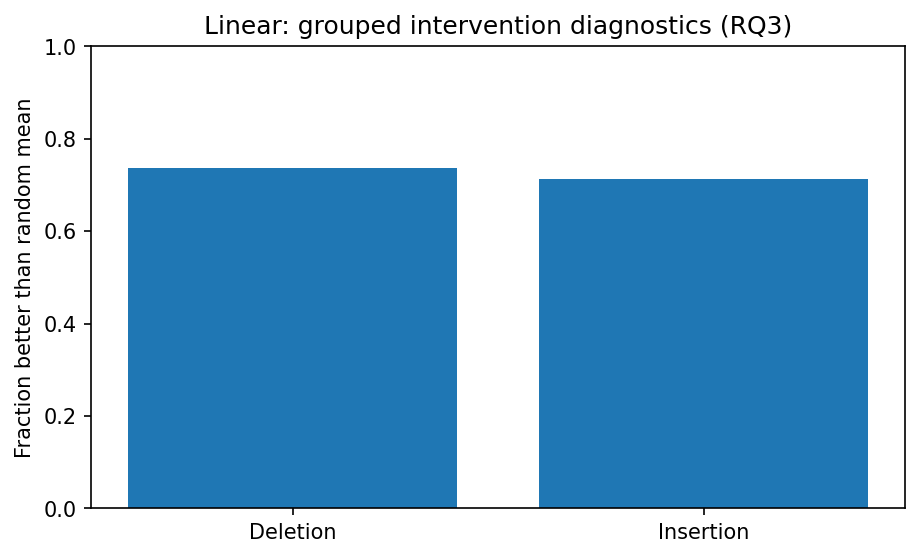

fig_rq1.png


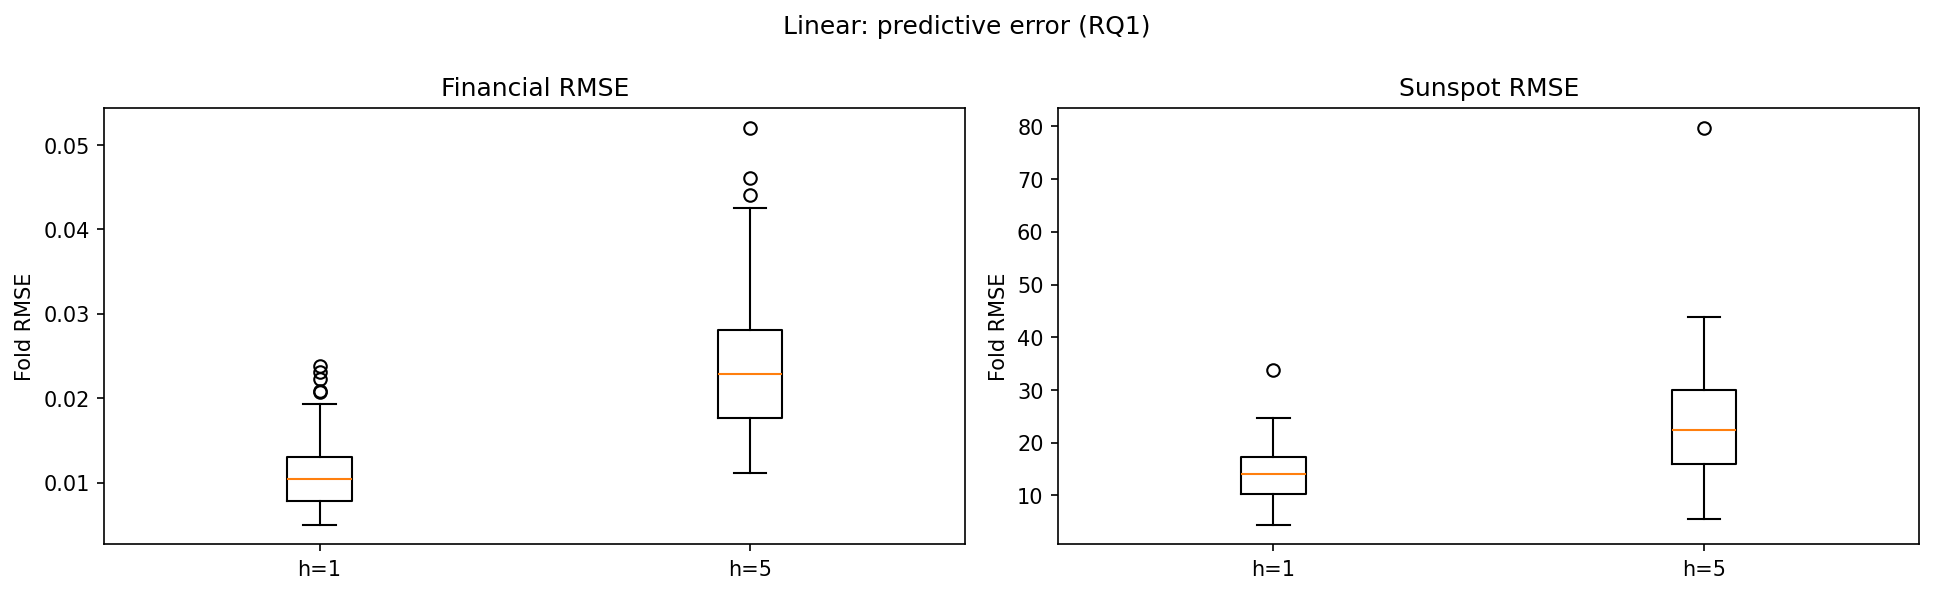

fig_shap_importance.png


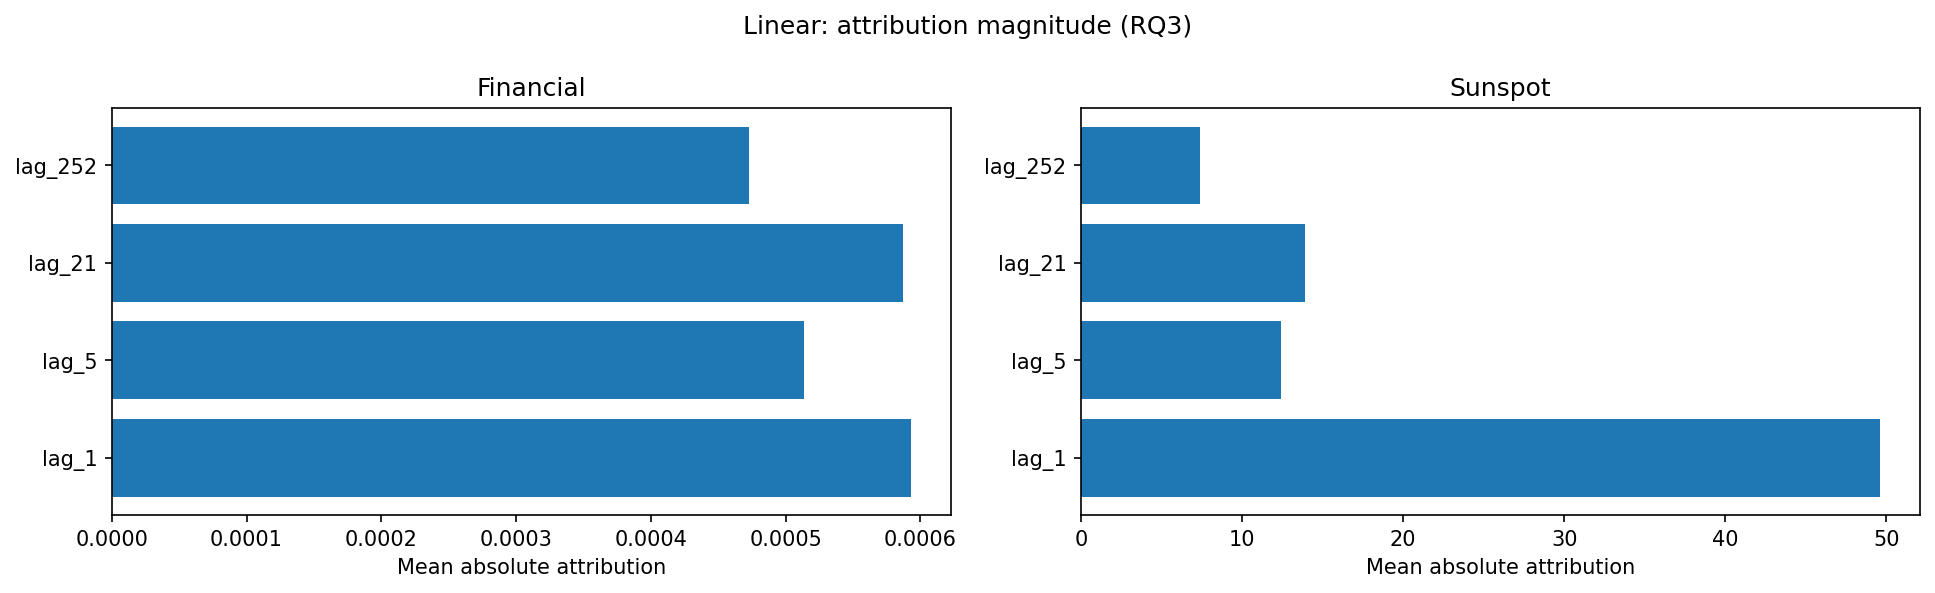

fig_stability.png


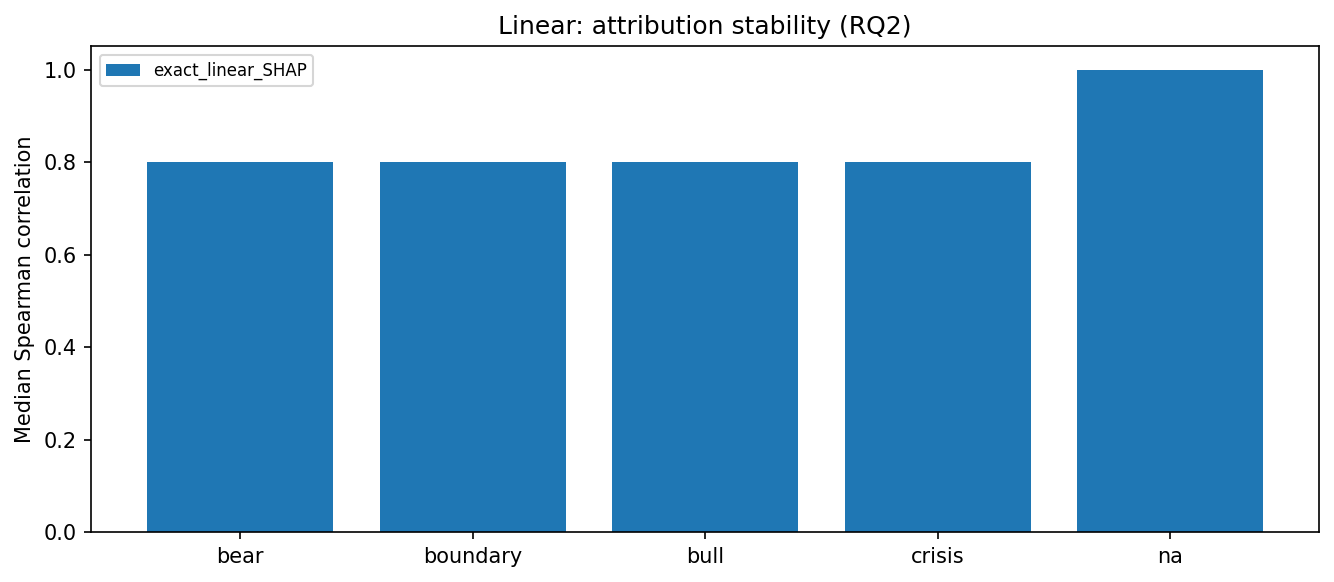

In [5]:
# Independent read-back of exported artifacts and checksum verification.
from IPython.display import Image, display
saved_audit = json.loads((OUT / 'evidence' / 'completion_audit.json').read_text())
assert saved_audit['missing_fold_units'] == 0
assert all(saved_audit['validation_checks'].values())
expected_hashes = json.loads((OUT / 'FILE_SHA256.json').read_text())
actual_hashes = {str(path.relative_to(OUT)): sha256(path) for path in sorted(OUT.rglob('*'))
                 if path.is_file() and path.name != 'FILE_SHA256.json'}
assert actual_hashes == expected_hashes
print('Read-back validation: PASS')
print('CSV artifacts:', len(list((OUT / 'tables').glob('*.csv'))))
print('Figures:', len(list((OUT / 'figures').glob('*.png'))))
display(pd.read_csv(OUT / 'tables' / 'fold_metrics.csv').head())
display(pd.read_csv(OUT / 'tables' / 'stability_summary.csv'))
for path in sorted((OUT / 'figures').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))

## Interpretation Boundary and Link to the Cross-Model Synthesis

This notebook supplies model-specific executed evidence. Seven-way accuracy rankings and pairwise significance statements are defined only after Notebook 08 restricts all models to the same forecast origins. Rolling and expanding tracks are related robustness analyses, not independent replications. Common origins equalize evaluation coverage, not information sets, tuning effort, or stochastic replication.

Stability means agreement between explanation vectors at matched probes across consecutive folds. Fold stability, tree-seed stability, and explanation-sampling stability are different constructs. No equivalent repeated-seed neural experiment or repeated KernelSHAP-sampling experiment for a fixed LSTM/TFT model is conducted here.

Faithfulness diagnostics test particular properties of the fitted predictor. Numerical additivity does not prove behavioral faithfulness; deletion, insertion, permutation, and surrogate fidelity can disagree because they intervene on different representations and distributions. None of these methods converts a lagged-price association into a genuine causal economic driver. Directional accuracy above 50% also does not establish investment profitability.

**Thesis connection:** Chapter 6 Discussion, Chapter 7 Limitations, and Chapter 8 Conclusion; §2.4.3 Dependent Features, Extrapolation, and Multiple Comparisons; §3.4.3 Statistical Drivers versus Genuine Economic Drivers. The economic-interpretation boundary is consistent with Cochrane (2005): statistical predictors alone do not identify an economic mechanism.
